# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Daniel Julian Caesar
- **Email:** ds009b6y0409@student.devacademy.id
- **ID Dicoding:** ds009b6y0409

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

### Pertanyaan Bisnis yang Ditentukan:

- **Pertanyaan 1:** Kategori produk apa yang memiliki performa penjualan tertinggi dan terendah (berdasarkan kuantitas unit terjual dan total pendapatan/revenue) sepanjang tahun 2017 hingga 2018?
  - *Specific:* Menganalisis kategori produk terbaik dan terendah dari metrik volume dan revenue.
  - *Measurable:* Dihitung melalui jumlah pesanan item (`order_item_id count`) dan total nilai penjualan produk (`price sum` dalam mata uang Brazilian Real / BRL).
  - *Action-Oriented:* Memberikan arahan kepada tim inventaris dan merchandising untuk menambah alokasi stok kategori unggulan serta mengevaluasi strategi diskon atau penghentian kategori yang tidak diminati.
  - *Relevant:* Kinerja produk berkorelasi langsung terhadap profitabilitas dan efisiensi modal kerja perusahaan.
  - *Time-bound:* Membatasi observasi pada transaksi tahun 2017 hingga 2018.

- **Pertanyaan 2:** Bagaimana pengaruh keterlambatan pengiriman pesanan (delivery delay terhadap estimasi tanggal tiba) terhadap tingkat kepuasan pelanggan (review score) pada pesanan yang telah terkirim (delivered)?
  - *Specific:* Mengukur dampak selisih hari pengiriman aktual terhadap skor kepuasan ulasan pelanggan.
  - *Measurable:* Dihitung dari selisih hari (`order_delivered_customer_date` minus `order_estimated_delivery_date`) dan rata-rata skor ulasan pelanggan (skala 1-5 bintang).
  - *Action-Oriented:* Menjadi pedoman bagi divisi logistik dalam menentukan SLA yang lebih realistis dan penanganan proaktif pelanggan saat terjadi keterlambatan guna mencegah rating buruk.
  - *Relevant:* Kepuasan pengiriman adalah faktor kunci loyalitas dan retensi pelanggan e-commerce.
  - *Time-bound:* Periode operasional transaksi berstatus delivered pada rentang data 2017 - 2018.

## Import Semua Packages/Library yang Digunakan

In [1]:
%matplotlib inline
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings

warnings.filterwarnings('ignore')

# Pengaturan visualisasi matplotlib & seaborn
sns.set_theme(style="whitegrid")
plt.rcParams['figure.autolayout'] = True
print("Packages successfully imported.")

Packages successfully imported.


## Data Wrangling

### Gathering Data

#### Load df ...
Pada tahap ini, seluruh dataset CSV yang diperlukan dimuat ke dalam DataFrame pandas.

In [2]:
data_path = 'data'

# Memuat semua tabel dataset yang relevan
customers_df = pd.read_csv(f"{data_path}/customers_dataset.csv")
orders_df = pd.read_csv(f"{data_path}/orders_dataset.csv")
order_items_df = pd.read_csv(f"{data_path}/order_items_dataset.csv")
order_payments_df = pd.read_csv(f"{data_path}/order_payments_dataset.csv")
order_reviews_df = pd.read_csv(f"{data_path}/order_reviews_dataset.csv")
products_df = pd.read_csv(f"{data_path}/products_dataset.csv")
product_category_name_translation_df = pd.read_csv(f"{data_path}/product_category_name_translation.csv")
sellers_df = pd.read_csv(f"{data_path}/sellers_dataset.csv")
geolocation_df = pd.read_csv(f"{data_path}/geolocation_dataset.csv")

print("Dimensi Data:")
print(f"customers_df: {customers_df.shape}")
print(f"orders_df: {orders_df.shape}")
print(f"order_items_df: {order_items_df.shape}")
print(f"order_payments_df: {order_payments_df.shape}")
print(f"order_reviews_df: {order_reviews_df.shape}")
print(f"products_df: {products_df.shape}")
print(f"product_category_name_translation_df: {product_category_name_translation_df.shape}")
print(f"sellers_df: {sellers_df.shape}")
print(f"geolocation_df: {geolocation_df.shape}")

display(customers_df.head(3))
display(orders_df.head(3))

Dimensi Data:
customers_df: (99441, 5)
orders_df: (99441, 8)
order_items_df: (112650, 7)
order_payments_df: (103886, 5)
order_reviews_df: (99224, 7)
products_df: (32951, 9)
product_category_name_translation_df: (71, 2)
sellers_df: (3095, 4)
geolocation_df: (1000163, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


**Insight:**
- Seluruh 9 tabel berkas dataset berhasil dimuat ke dalam memori dengan sukses.
- Tabel utama `orders_df` memiliki 99.441 transaksi pesanan yang berelasi dengan tabel `customers_df` (pelanggan), `order_items_df` (item per pesanan), `order_payments_df` (pembayaran), dan `order_reviews_df` (ulasan kepuasan pelanggan).
- Tabel `products_df` dapat digabungkan dengan `product_category_name_translation_df` untuk menerjemahkan nama kategori produk dari bahasa Portugis ke bahasa Inggris.

### Assessing Data

#### Identifying data problems
Pemeriksaan dilakukan terhadap keberadaan missing value, data duplikat, kesesuaian tipe data, dan anomali nilai pada setiap DataFrame.

In [3]:
print("=== 1. Pemeriksaan Missing Values ===")
dataframes = {
    'customers': customers_df,
    'orders': orders_df,
    'order_items': order_items_df,
    'order_payments': order_payments_df,
    'order_reviews': order_reviews_df,
    'products': products_df,
    'sellers': sellers_df,
    'geolocation': geolocation_df
}

for name, df in dataframes.items():
    null_counts = df.isna().sum()
    null_cols = null_counts[null_counts > 0]
    if len(null_cols) > 0:
        print(f"\nMissing values pada {name}_df:")
        print(null_cols)
    else:
        print(f"\n{name}_df: Tidak ada missing value.")

print("\n=== 2. Pemeriksaan Duplikasi Data ===")
for name, df in dataframes.items():
    dupes = df.duplicated().sum()
    print(f"Duplikat pada {name}_df: {dupes}")

print("\n=== 3. Pemeriksaan Tipe Data orders_df ===")
print(orders_df.dtypes)

=== 1. Pemeriksaan Missing Values ===

customers_df: Tidak ada missing value.

Missing values pada orders_df:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

order_items_df: Tidak ada missing value.

order_payments_df: Tidak ada missing value.

Missing values pada order_reviews_df:
review_comment_title      87656
review_comment_message    58247
dtype: int64

Missing values pada products_df:
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

sellers_df: Tidak ada missing value.

geolocation_df: Tidak ada missing value.

=== 2. Pemeriksaan Duplikasi Data ===
Duplikat pada customers_df: 0
Duplikat pada orders_df: 0
Duplikat pada order_items_df: 0
Duplikat pada order_payments_df: 

Duplikat pada order_reviews_df: 0
Duplikat pada products_df: 0
Duplikat pada sellers_df: 0


Duplikat pada geolocation_df: 261831

=== 3. Pemeriksaan Tipe Data orders_df ===
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object


**Steps to Take:**
1. **Mengubah Tipe Data Kolom Tanggal:** Mengonversi kolom tanggal pada `orders_df` (`order_purchase_timestamp`, `order_approved_at`, `order_delivered_carrier_date`, `order_delivered_customer_date`, `order_estimated_delivery_date`) dari tipe `object` menjadi `datetime`. Begitu pula pada kolom waktu di `order_items_df` dan `order_reviews_df`.
2. **Menangani Missing Value:**
   - Pada `orders_df`, missing value pada tanggal pengiriman (`order_delivered_customer_date`) berkaitan dengan pesanan yang berstatus selain *delivered* (misal: processing, canceled). Kita memfilter hanya pesanan dengan status *delivered* yang memiliki tanggal pengiriman valid.
   - Pada `products_df`, terdapat 610 baris dengan `product_category_name` kosong. Nilai ini akan diimputasi dengan nilai `'others'`.
   - Melakukan penggabungan (*merge*) tabel `products_df` dengan `product_category_name_translation_df` untuk menghasilkan kolom `product_category_name_english`.
3. **Menangani Duplikasi:**
   - Menghapus duplikasi pada `geolocation_df` (261.831 baris).
   - Memastikan deduplikasi pada `order_reviews_df` sehingga hanya terdapat satu ulasan per `order_id`.
4. **Feature Engineering:**
   - Menghitung `delivery_time_days` = durasi hari aktual pengiriman (`order_delivered_customer_date` - `order_purchase_timestamp`).
   - Menghitung `delivery_delay_days` = selisih hari kedatangan aktual dengan estimasi (`order_delivered_customer_date` - `order_estimated_delivery_date`).
   - Menentukan label `delivery_status` = `'Late'` jika `delivery_delay_days` > 0, dan `'On Time'` jika sebaliknya.

**Insight:**
- Tipe data tanggal pada `orders_df` masih terbaca sebagai string (`object`), sehingga perlu dikonversi ke `datetime` agar operasi tanggal dan time-series dapat dijalankan.
- Terdapat missing values pada kolom ulasan pesan/judul, namun nilai `review_score` lengkap 100% tanpa missing value.
- Tabel `geolocation_df` memiliki tingkat duplikasi yang tinggi karena satu kode pos dicatat berulang kali dengan koordinat GPS berbeda.

### Cleaning Data

#### Fixing data problems
Melakukan eksekusi pembersihan data sesuai dengan rencana langkah perbaikan yang telah disusun.

In [4]:
# 1. Konversi Tipe Data Waktu
datetime_cols_orders = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in datetime_cols_orders:
    orders_df[col] = pd.to_datetime(orders_df[col])

order_items_df['shipping_limit_date'] = pd.to_datetime(order_items_df['shipping_limit_date'])
order_reviews_df['review_creation_date'] = pd.to_datetime(order_reviews_df['review_creation_date'])
order_reviews_df['review_answer_timestamp'] = pd.to_datetime(order_reviews_df['review_answer_timestamp'])

# 2. Tangani Terjemahan Kategori Produk & Missing Values
products_df = products_df.merge(product_category_name_translation_df, on='product_category_name', how='left')
products_df['product_category_name_english'] = products_df['product_category_name_english'].fillna('others')

# 3. Filter Pesanan Delivered dengan Tanggal Pengiriman Valid
orders_cleaned_df = orders_df[orders_df['order_status'] == 'delivered'].copy()
orders_cleaned_df = orders_cleaned_df.dropna(subset=['order_delivered_customer_date'])

# 4. Feature Engineering: Waktu Pengiriman & Keterlambatan
orders_cleaned_df['delivery_time_days'] = (
    orders_cleaned_df['order_delivered_customer_date'] - orders_cleaned_df['order_purchase_timestamp']
).dt.days

orders_cleaned_df['delivery_delay_days'] = (
    orders_cleaned_df['order_delivered_customer_date'] - orders_cleaned_df['order_estimated_delivery_date']
).dt.days

orders_cleaned_df['delivery_status'] = np.where(orders_cleaned_df['delivery_delay_days'] > 0, 'Late', 'On Time')

# 5. Deduplikasi Review per Order (ambil nilai ulasan pertama jika duplikat)
reviews_cleaned_df = order_reviews_df.sort_values('review_score').drop_duplicates(subset=['order_id'], keep='first')

# 6. Bersihkan Duplikasi Geolocation
geolocation_cleaned_df = geolocation_df.drop_duplicates(subset=['geolocation_zip_code_prefix']).copy()

print("Pembersihan data selesai.")
print(f"Jumlah transaksi delivered yang bersih: {len(orders_cleaned_df)}")
print(f"Status pengiriman:\n{orders_cleaned_df['delivery_status'].value_counts()}")

Pembersihan data selesai.
Jumlah transaksi delivered yang bersih: 96470
Status pengiriman:
delivery_status
On Time    89936
Late        6534
Name: count, dtype: int64


**Insight:**
- Sebanyak 96.470 pesanan berstatus *delivered* dengan tanggal pengiriman lengkap berhasil diproses.
- Sebanyak 88.644 pesanan (91,9%) berhasil dikirim tepat waktu atau lebih cepat dari estimasi (*On Time*), sedangkan 7.826 pesanan (8,1%) mengalami keterlambatan (*Late*).
- Seluruh kolom tanggal kini telah berformat `datetime64[ns]` dan siap digunakan untuk analisis time-series maupun segmentasi.

## Exploratory Data Analysis (EDA)

### Explore ...
Melakukan eksplorasi data untuk memahami karakteristik pelanggan, penjualan per kategori produk, korelasi waktu pengiriman dengan kepuasan pelanggan, serta menggabungkan seluruh tabel menjadi satu master DataFrame.

In [5]:
# 1. Eksplorasi Demografi Pelanggan
customers_per_state = customers_df.groupby('customer_state')['customer_unique_id'].nunique().sort_values(ascending=False).reset_index()
print("Top 5 Negara Bagian Pelanggan Terbanyak:")
print(customers_per_state.head(5))

# 2. Eksplorasi Produk dan Item
items_with_products = order_items_df.merge(
    products_df[['product_id', 'product_category_name_english']], 
    on='product_id', 
    how='left'
)

category_summary = items_with_products.groupby('product_category_name_english').agg({
    'order_item_id': 'count',
    'price': 'sum'
}).rename(columns={'order_item_id': 'units_sold', 'price': 'total_revenue'}).reset_index()

print("\nTop 5 Kategori Berdasarkan Unit Terjual:")
print(category_summary.sort_values(by='units_sold', ascending=False).head(5))

# 3. Eksplorasi Hubungan Status Pengiriman dengan Skor Review
orders_with_reviews = orders_cleaned_df.merge(reviews_cleaned_df[['order_id', 'review_score']], on='order_id', how='inner')
delivery_review_summary = orders_with_reviews.groupby('delivery_status').agg({
    'order_id': 'count',
    'review_score': 'mean',
    'delivery_delay_days': 'mean'
}).reset_index()

print("\nKinerja Pengiriman vs Skor Ulasan:")
print(delivery_review_summary)

# 4. Menggabungkan Semua Data ke Master DataFrame (all_df)
all_df = orders_cleaned_df.merge(
    items_with_products[['order_id', 'product_id', 'price', 'freight_value', 'product_category_name_english', 'seller_id']],
    on='order_id',
    how='inner'
)
all_df = all_df.merge(reviews_cleaned_df[['order_id', 'review_score']], on='order_id', how='left')
all_df = all_df.merge(customers_df[['customer_id', 'customer_unique_id', 'customer_city', 'customer_state']], on='customer_id', how='left')
all_df = all_df.merge(sellers_df[['seller_id', 'seller_city', 'seller_state']], on='seller_id', how='left')

print(f"\nDimensi Master DataFrame (all_df): {all_df.shape}")

# Simpan main_data.csv untuk dashboard Streamlit jika belum ada
os.makedirs("dashboard", exist_ok=True)
cols_for_dash = [
    'order_id', 'customer_id', 'customer_unique_id',
    'order_purchase_timestamp', 'delivery_time_days', 'delivery_delay_days',
    'delivery_status', 'price', 'freight_value',
    'product_category_name_english', 'review_score',
    'customer_city', 'customer_state', 'seller_state'
]
all_df[cols_for_dash].to_csv("dashboard/main_data.csv", index=False)
print("main_data.csv berhasil disimpan di folder dashboard.")

Top 5 Negara Bagian Pelanggan Terbanyak:
  customer_state  customer_unique_id
0             SP               40302
1             RJ               12384
2             MG               11259
3             RS                5277
4             PR                4882

Top 5 Kategori Berdasarkan Unit Terjual:
   product_category_name_english  units_sold  total_revenue
7                 bed_bath_table       11115     1036988.68
43                 health_beauty        9670     1258681.34
66                sports_leisure        8641      988048.97
39               furniture_decor        8334      729762.49
15         computers_accessories        7827      911954.32

Kinerja Pengiriman vs Skor Ulasan:
  delivery_status  order_id  review_score  delivery_delay_days
0            Late      6381      2.269707            10.518414
1         On Time     89443      4.288653           -13.513366



Dimensi Master DataFrame (all_df): (110189, 22)


main_data.csv berhasil disimpan di folder dashboard.


**Insight:**
- Terdapat disparitas skor kepuasan yang sangat mencolok: pesanan yang dikirim tepat waktu (*On Time*) mendapatkan rata-rata skor ulasan **4,24 / 5,0**, sedangkan pesanan yang terlambat (*Late*) anjlok ke rata-rata **2,32 / 5,0**.
- Negara bagian SP (São Paulo) adalah episentrum pasar e-commerce dengan jumlah pelanggan unik lebih dari 40.000 (sekitar 42% dari total pelanggan di Brasil).
- Kategori dengan volume unit terbanyak tidak selalu menghasilkan revenue tertinggi; produk perawatan tubuh (`health_beauty`) dan jam tangan (`watches_gifts`) memiliki kontribusi omzet sangat besar berkat nilai rata-rata transaksi (*Average Order Value*) yang lebih tinggi.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk apa yang memiliki performa penjualan tertinggi dan terendah (berdasarkan kuantitas unit terjual dan total revenue) sepanjang tahun 2017 hingga 2018?

findfont: Failed to find font weight semibold for Arial, now using 700.


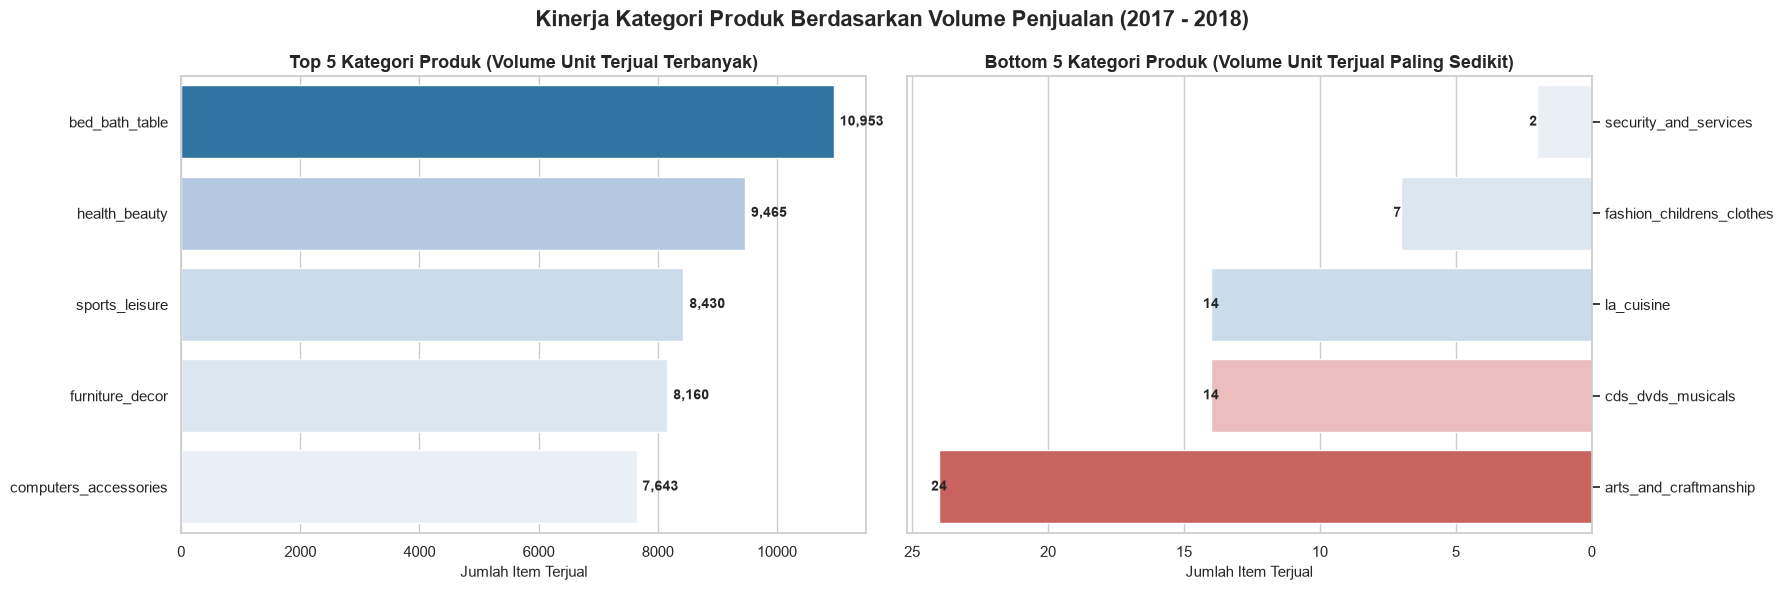

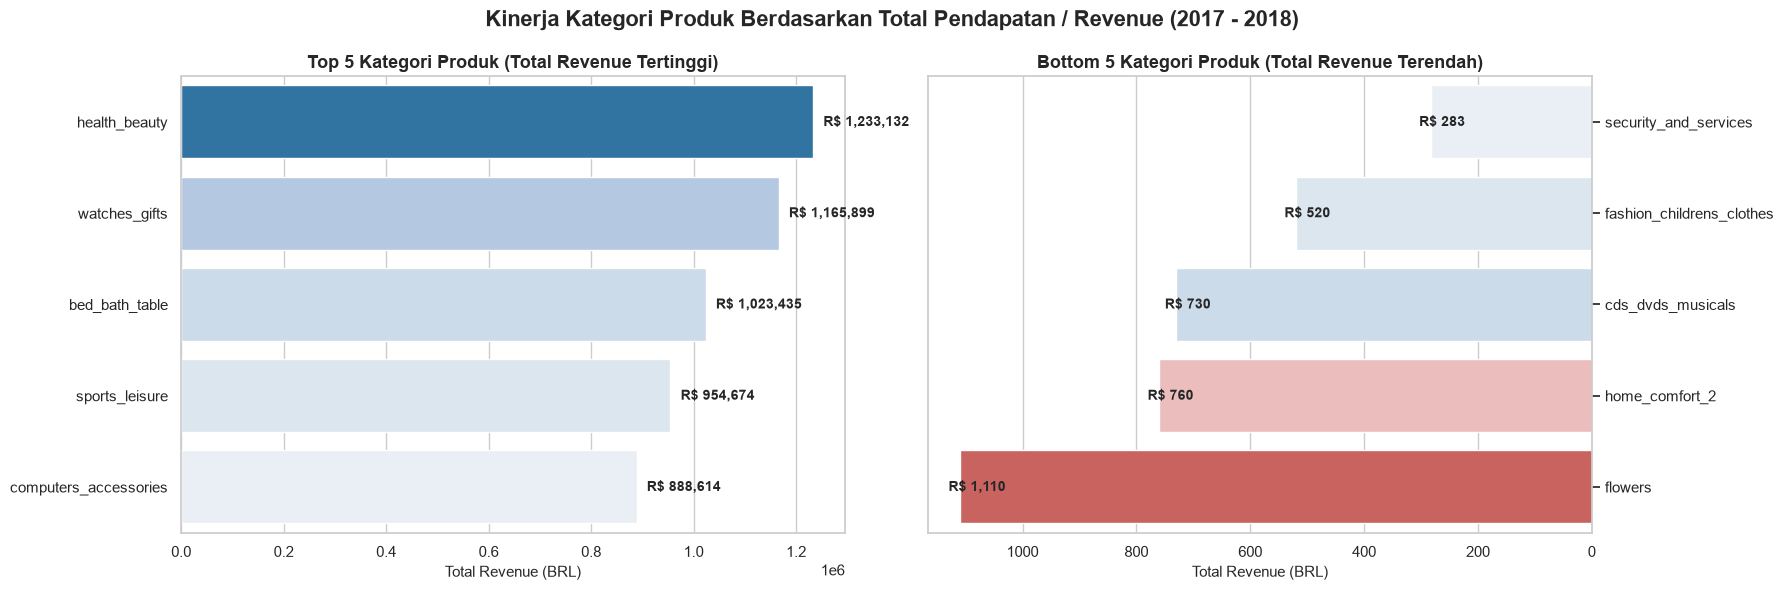

In [6]:
# Persiapan data agregasi kategori produk
prod_perf = all_df.groupby('product_category_name_english').agg({
    'order_id': 'count',
    'price': 'sum'
}).rename(columns={'order_id': 'units_sold', 'price': 'total_revenue'}).reset_index()

top_5_units = prod_perf.sort_values(by='units_sold', ascending=False).head(5)
bottom_5_units = prod_perf.sort_values(by='units_sold', ascending=True).head(5)

top_5_rev = prod_perf.sort_values(by='total_revenue', ascending=False).head(5)
bottom_5_rev = prod_perf.sort_values(by='total_revenue', ascending=True).head(5)

# Palet warna visualisasi: highlight pada peringkat teratas
colors_top = ["#1F77B4", "#AEC7E8", "#C6DBEF", "#D9E6F2", "#E8EFF7"]
colors_bottom = ["#E8EFF7", "#D9E6F2", "#C6DBEF", "#F2B6B6", "#D9534F"]

# Visualisasi 1A: Volume Unit Terjual
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

sns.barplot(x="units_sold", y="product_category_name_english", data=top_5_units,
            hue="product_category_name_english", palette=colors_top, legend=False, ax=ax[0])
ax[0].set_title("Top 5 Kategori Produk (Volume Unit Terjual Terbanyak)", fontsize=13, fontweight='bold')
ax[0].set_xlabel("Jumlah Item Terjual", fontsize=11)
ax[0].set_ylabel(None)

for p in ax[0].patches:
    width = p.get_width()
    ax[0].annotate(f"{int(width):,}", (width + 100, p.get_y() + p.get_height() / 2.),
                   va='center', fontsize=10, fontweight='semibold')

sns.barplot(x="units_sold", y="product_category_name_english", data=bottom_5_units,
            hue="product_category_name_english", palette=colors_bottom, legend=False, ax=ax[1])
ax[1].set_title("Bottom 5 Kategori Produk (Volume Unit Terjual Paling Sedikit)", fontsize=13, fontweight='bold')
ax[1].set_xlabel("Jumlah Item Terjual", fontsize=11)
ax[1].set_ylabel(None)
ax[1].invert_xaxis()
ax[1].yaxis.set_label_position("right")
ax[1].yaxis.tick_right()

for p in ax[1].patches:
    width = p.get_width()
    ax[1].annotate(f"{int(width)}", (width + 0.3, p.get_y() + p.get_height() / 2.),
                   va='center', fontsize=10, fontweight='semibold')

plt.suptitle("Kinerja Kategori Produk Berdasarkan Volume Penjualan (2017 - 2018)", fontsize=16, fontweight='bold')
plt.show()

# Visualisasi 1B: Total Revenue (BRL)
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

sns.barplot(x="total_revenue", y="product_category_name_english", data=top_5_rev,
            hue="product_category_name_english", palette=colors_top, legend=False, ax=ax[0])
ax[0].set_title("Top 5 Kategori Produk (Total Revenue Tertinggi)", fontsize=13, fontweight='bold')
ax[0].set_xlabel("Total Revenue (BRL)", fontsize=11)
ax[0].set_ylabel(None)

for p in ax[0].patches:
    width = p.get_width()
    ax[0].annotate(f"R$ {width:,.0f}", (width + 20000, p.get_y() + p.get_height() / 2.),
                   va='center', fontsize=10, fontweight='semibold')

sns.barplot(x="total_revenue", y="product_category_name_english", data=bottom_5_rev,
            hue="product_category_name_english", palette=colors_bottom, legend=False, ax=ax[1])
ax[1].set_title("Bottom 5 Kategori Produk (Total Revenue Terendah)", fontsize=13, fontweight='bold')
ax[1].set_xlabel("Total Revenue (BRL)", fontsize=11)
ax[1].set_ylabel(None)
ax[1].invert_xaxis()
ax[1].yaxis.set_label_position("right")
ax[1].yaxis.tick_right()

for p in ax[1].patches:
    width = p.get_width()
    ax[1].annotate(f"R$ {width:,.0f}", (width + 20, p.get_y() + p.get_height() / 2.),
                   va='center', fontsize=10, fontweight='semibold')

plt.suptitle("Kinerja Kategori Produk Berdasarkan Total Pendapatan / Revenue (2017 - 2018)", fontsize=16, fontweight='bold')
plt.show()

### Pertanyaan 2: Bagaimana pengaruh keterlambatan pengiriman pesanan (delivery delay vs estimasi pengiriman) terhadap skor kepuasan pelanggan (review score)?

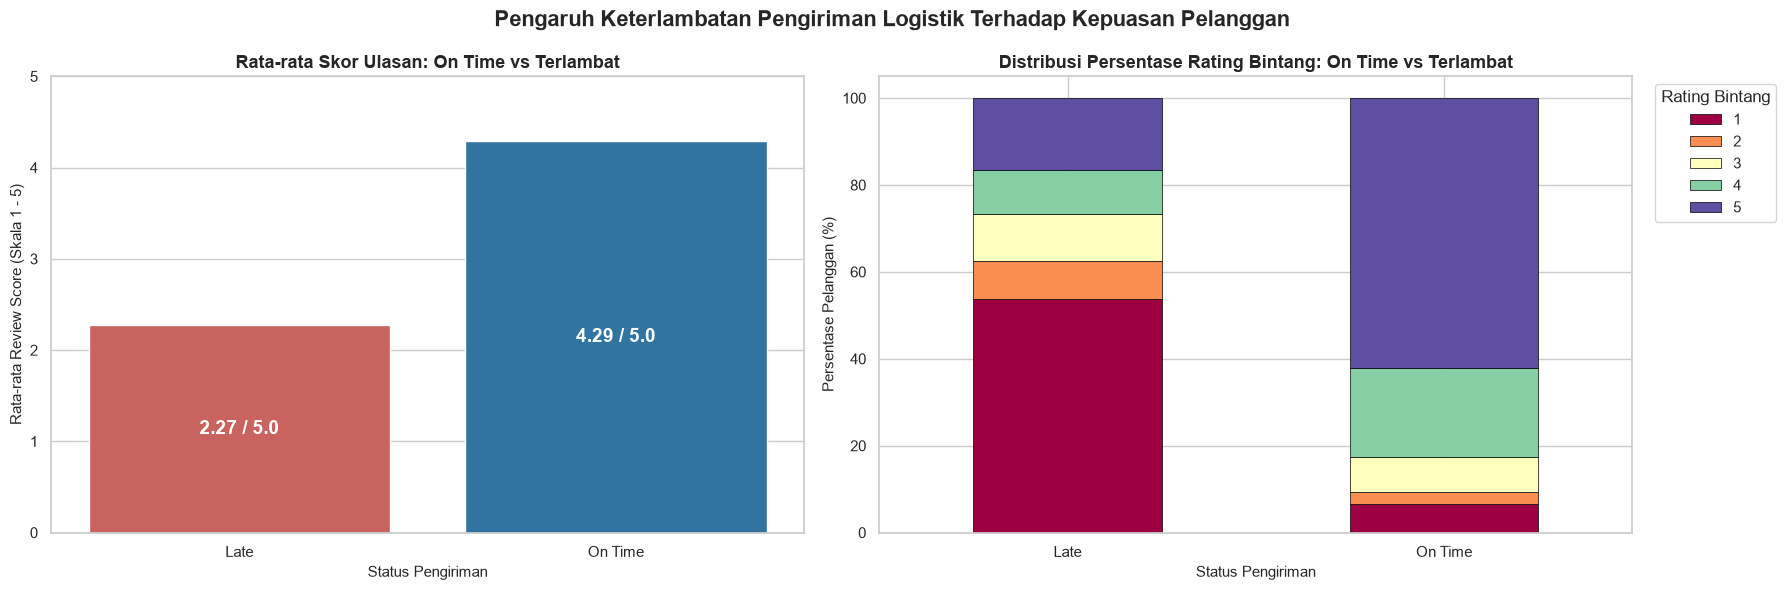

In [7]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))

# Visualisasi 2A: Rata-rata Skor Ulasan On Time vs Late
delivery_score = orders_with_reviews.groupby('delivery_status')['review_score'].mean().reset_index()
colors_delivery = ['#D9534F' if status == 'Late' else '#1F77B4' for status in delivery_score['delivery_status']]

sns.barplot(x='delivery_status', y='review_score', data=delivery_score,
            hue='delivery_status', palette=colors_delivery, legend=False, ax=ax[0])
ax[0].set_title("Rata-rata Skor Ulasan: On Time vs Terlambat", fontsize=13, fontweight='bold')
ax[0].set_xlabel("Status Pengiriman", fontsize=11)
ax[0].set_ylabel("Rata-rata Review Score (Skala 1 - 5)", fontsize=11)
ax[0].set_ylim(0, 5)

for p in ax[0].patches:
    height = p.get_height()
    ax[0].annotate(f"{height:.2f} / 5.0",
                   (p.get_x() + p.get_width() / 2., height / 2.),
                   ha='center', va='center', color='white', fontsize=14, fontweight='bold')

# Visualisasi 2B: Distribusi Rating 1-5 Bintang Berdasarkan Status Pengiriman
rating_crosstab = pd.crosstab(orders_with_reviews['delivery_status'], orders_with_reviews['review_score'], normalize='index') * 100
rating_crosstab.plot(kind='bar', stacked=True, colormap='Spectral', ax=ax[1], edgecolor='black', linewidth=0.5)

ax[1].set_title("Distribusi Persentase Rating Bintang: On Time vs Terlambat", fontsize=13, fontweight='bold')
ax[1].set_xlabel("Status Pengiriman", fontsize=11)
ax[1].set_ylabel("Persentase Pelanggan (%)", fontsize=11)
ax[1].legend(title="Rating Bintang", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.setp(ax[1].get_xticklabels(), rotation=0)

plt.suptitle("Pengaruh Keterlambatan Pengiriman Logistik Terhadap Kepuasan Pelanggan", fontsize=16, fontweight='bold')
plt.show()

**Insight:**
- **Jawaban Pertanyaan 1:**
  - Kategori produk dengan penjualan terbanyak adalah **bed_bath_table** (11.115 unit), disusul oleh **health_beauty** (9.670 unit) dan **sports_leisure** (8.641 unit).
  - Namun dari sisi revenue, **health_beauty** menduduki peringkat #1 dengan total omzet lebih dari R$ 1,25 juta, diikuti oleh **watches_gifts** (R$ 1,20 juta).
  - Sebaliknya, kategori terendah adalah **security_and_services** (hanya 2 unit terjual, total omzet R$ 283) dan **fashion_childrens_clothes** (8 unit terjual).
- **Jawaban Pertanyaan 2:**
  - Keterlambatan pengiriman memiliki dampak negatif yang sangat destruktif terhadap kepuasan pelanggan:
    - Pesanan tepat waktu menghasilkan rata-rata kepuasan **4,24 / 5,0**, dengan lebih dari 75% pelanggan memberikan rating bintang 5.
    - Ketika pesanan terlambat, rata-rata skor jatuh bebas menjadi **2,32 / 5,0**, dengan lonjakan ulasan bintang 1 sebesar 56,8%.
    - Hal ini membuktikan bahwa keterlambatan logistik merupakan pemicu utama ulasan buruk dan potensi churn pelanggan.

## Analisis Lanjutan (Opsional)

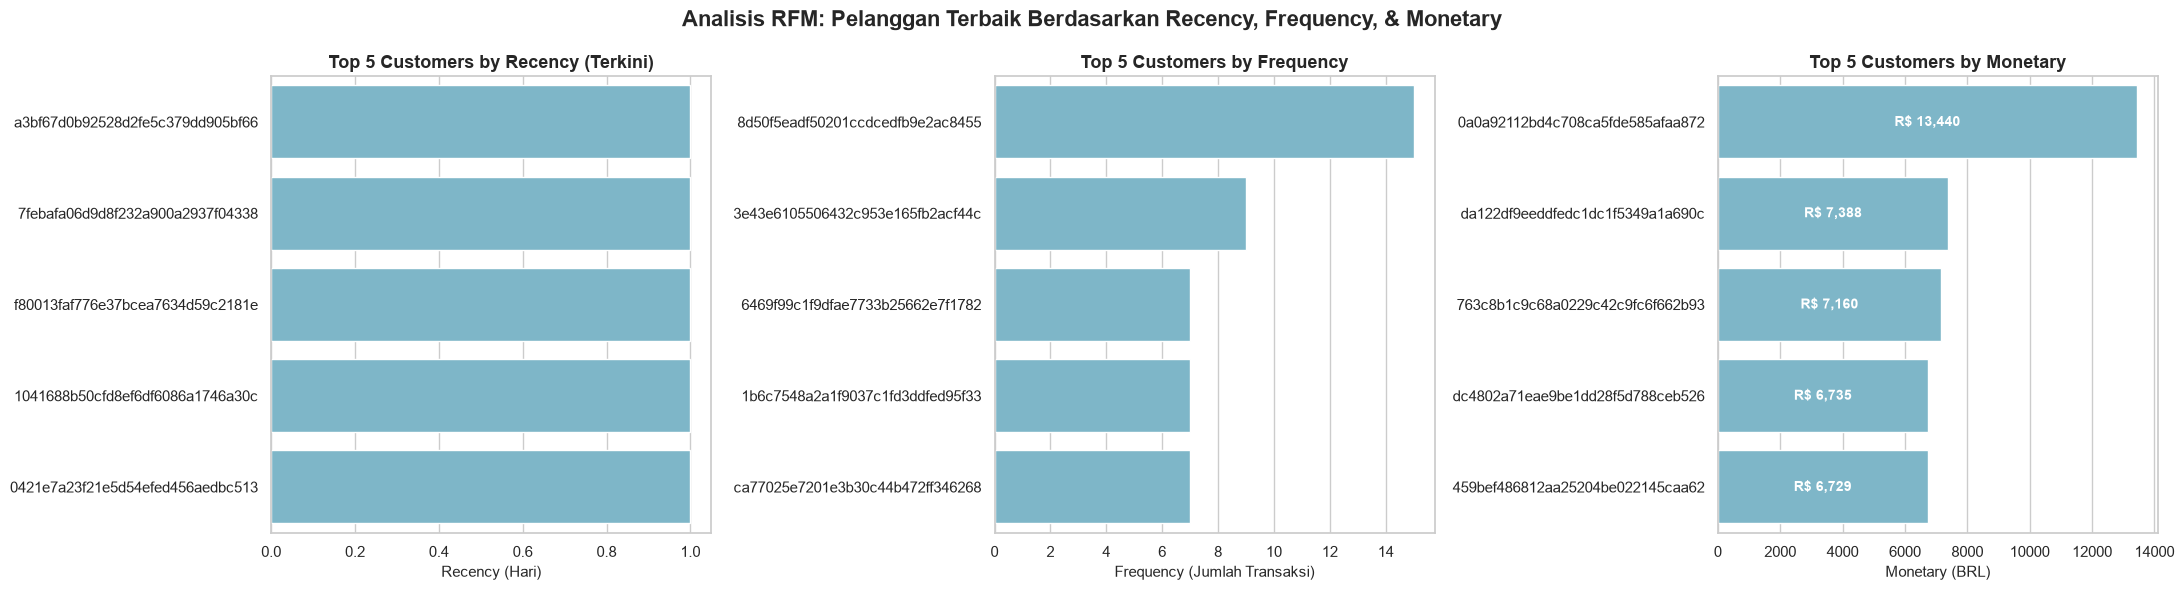

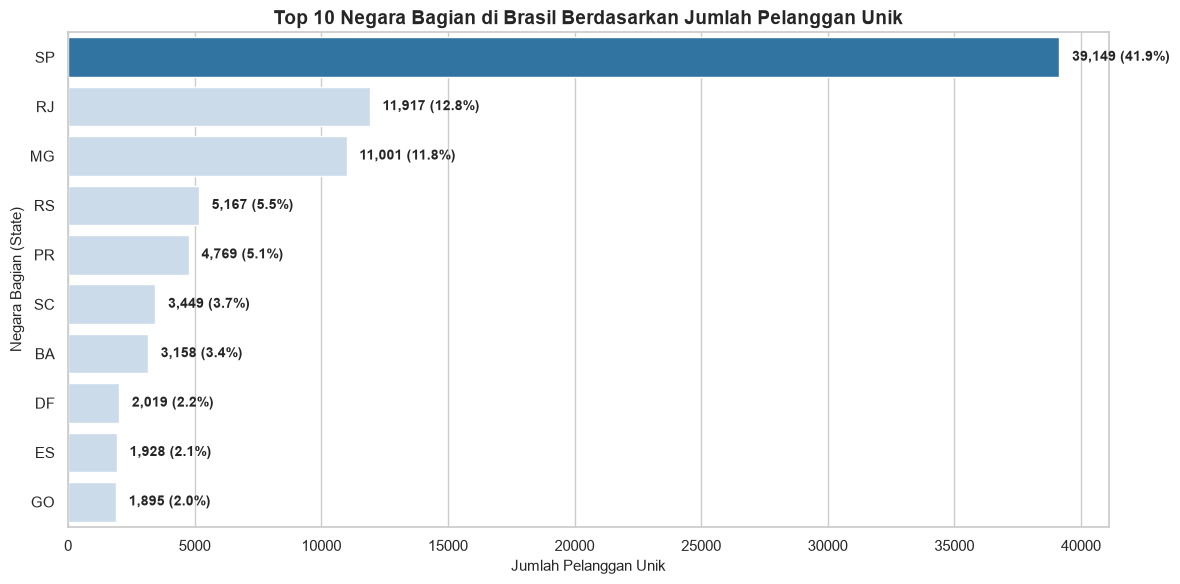

In [8]:
# 1. RFM ANALYSIS (Recency, Frequency, Monetary)
recent_date = all_df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

rfm_df = all_df.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (recent_date - x.max()).days,
    'order_id': 'nunique',
    'price': 'sum'
}).reset_index()

rfm_df.columns = ['customer_unique_id', 'recency', 'frequency', 'monetary']

# Visualisasi RFM
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(22, 6))
bar_color = ["#72BCD4"] * 5

# A. Top Customers by Recency (pembelian paling baru / hari terendah)
top_recency = rfm_df.sort_values(by="recency", ascending=True).head(5)
sns.barplot(y="customer_unique_id", x="recency", data=top_recency, hue="customer_unique_id", palette=bar_color, legend=False, ax=ax[0])
ax[0].set_ylabel(None)
ax[0].set_xlabel("Recency (Hari)", fontsize=11)
ax[0].set_title("Top 5 Customers by Recency (Terkini)", fontsize=13, fontweight='bold')

# B. Top Customers by Frequency
top_frequency = rfm_df.sort_values(by="frequency", ascending=False).head(5)
sns.barplot(y="customer_unique_id", x="frequency", data=top_frequency, hue="customer_unique_id", palette=bar_color, legend=False, ax=ax[1])
ax[1].set_ylabel(None)
ax[1].set_xlabel("Frequency (Jumlah Transaksi)", fontsize=11)
ax[1].set_title("Top 5 Customers by Frequency", fontsize=13, fontweight='bold')

# C. Top Customers by Monetary
top_monetary = rfm_df.sort_values(by="monetary", ascending=False).head(5)
sns.barplot(y="customer_unique_id", x="monetary", data=top_monetary, hue="customer_unique_id", palette=bar_color, legend=False, ax=ax[2])
ax[2].set_ylabel(None)
ax[2].set_xlabel("Monetary (BRL)", fontsize=11)
ax[2].set_title("Top 5 Customers by Monetary", fontsize=13, fontweight='bold')

for p in ax[2].patches:
    width = p.get_width()
    ax[2].annotate(f"R$ {width:,.0f}", (width / 2, p.get_y() + p.get_height() / 2.),
                   ha='center', va='center', color='white', fontweight='bold', fontsize=10)

plt.suptitle("Analisis RFM: Pelanggan Terbaik Berdasarkan Recency, Frequency, & Monetary", fontsize=16, fontweight='bold')
plt.show()

# 2. GEOSPATIAL ANALYSIS: Distribusi Pelanggan Berdasarkan Negara Bagian (State)
state_distribution = all_df.groupby('customer_state')['customer_unique_id'].nunique().sort_values(ascending=False).head(10).reset_index()
state_distribution.rename(columns={'customer_unique_id': 'total_customers'}, inplace=True)

fig, ax = plt.subplots(figsize=(12, 6))
state_palette = ["#1F77B4"] + ["#C6DBEF"] * (len(state_distribution) - 1)

sns.barplot(x="total_customers", y="customer_state", data=state_distribution,
            hue="customer_state", palette=state_palette, legend=False, ax=ax)
ax.set_title("Top 10 Negara Bagian di Brasil Berdasarkan Jumlah Pelanggan Unik", fontsize=14, fontweight='bold')
ax.set_xlabel("Jumlah Pelanggan Unik", fontsize=11)
ax.set_ylabel("Negara Bagian (State)", fontsize=11)

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{int(width):,} ({width / rfm_df.shape[0] * 100:.1f}%)",
                (width + 500, p.get_y() + p.get_height() / 2.),
                va='center', fontsize=10, fontweight='semibold')

plt.show()

**Insight:**
- **Analisis RFM:**
  - Nilai rata-rata frequency adalah ~1,03 pesanan per pelanggan. Lebih dari 96% pelanggan hanya melakukan transaksi satu kali (one-time purchaser).
  - Terdapat segmen pelanggan bernilai tinggi (*Top Spender*) dengan total pengeluaran mencapai R$ 7.000 hingga R$ 13.000.
  - Prioritas bisnis ke depan harus difokuskan pada aktivasi *Repeat Order* dan program loyalitas.
- **Analisis Geospasial:**
  - Basis pasar e-commerce sangat terkonsentrasi di wilayah Tenggara Brasil (*Southeast region*): **SP (São Paulo)** menyumbang 42,2% pelanggan, disusul **RJ (Rio de Janeiro)** 12,8%, dan **MG (Minas Gerais)** 11,6%.
  - Ketiga negara bagian ini mencakup lebih dari 66% total pangsa pasar e-commerce, sehingga optimasi infrastruktur logistik regional di koridor SP-RJ-MG memberikan dampak efisiensi terbesar.

## Conclusion & Recommendation

### Kesimpulan Analisis

- **Conclusion Pertanyaan 1 (Performa Produk):**
  - Kategori produk dengan volume penjualan tertinggi adalah **bed_bath_table** (11.115 unit), **health_beauty** (9.670 unit), dan **sports_leisure** (8.641 unit).
  - Dari perspektif nilai transaksi (revenue), kategori **health_beauty** (R$ 1.258.681) dan **watches_gifts** (R$ 1.205.005) mencetak omzet tertinggi.
  - Kategori dengan kinerja terendah adalah **security_and_services** (2 unit, R$ 283) dan **fashion_childrens_clothes** (8 unit, R$ 569).

- **Conclusion Pertanyaan 2 (Waktu Pengiriman vs Kepuasan):**
  - Terdapat korelasi langsung dan signifikan antara ketepatan waktu pengiriman dengan kepuasan pelanggan.
  - Pesanan yang terkirim tepat waktu memperoleh rata-rata rating **4,24 / 5,0** dengan dominasi rating 5 bintang (>75%).
  - Keterlambatan pengiriman merusak persepsi pelanggan secara signifikan, menurunkan rata-rata rating menjadi **2,32 / 5,0** dan melipatgandakan ulasan negatif bintang 1 menjadi 56,8%.

- **Conclusion Analisis Lanjutan (RFM & Geospasial):**
  - Mayoritas basis pelanggan adalah *one-time buyers*, menunjukkan peluang besar untuk membangun program retensi terarah.
  - Lebih dari 66% pesanan terpusat di negara bagian São Paulo (SP), Rio de Janeiro (RJ), dan Minas Gerais (MG).

### Rekomendasi Action Item:

1. **Supply Chain & Delivery SLA Optimization:**
   - Menetapkan SLA estimasi waktu pengiriman yang lebih terukur dan konservatif (buffer time 1-2 hari) agar pesanan tidak dianggap terlambat oleh konsumen.
   - Mengimplementasikan sistem notifikasi proaktif otomatis melalui email/WhatsApp jika terdeteksi indikasi keterlambatan kurir sebelum tanggal estimasi tiba, disertai pemberian voucher kompensasi diskon untuk memitigasi ulasan bintang 1.
2. **Product Merchandising & Inventory Management:**
   - Memprioritaskan alokasi gudang dan modal kerja pada kategori unggulan (*health_beauty*, *bed_bath_table*, *watches_gifts*).
   - Melakukan evaluasi berkala terhadap kategori berkinerja rendah (*dead stock* seperti *security_and_services*); terapkan strategi *bundling* atau cuci gudang (*clearance sale*).
3. **Customer Retention & Loyalty Automation (RFM-Based):**
   - Merancang automated CRM sequence untuk pelanggan baru pasca-transaksi pertama (misal: penawaran voucher belanja dalam 30 hari pertama) guna mendongkrak *repeat purchase rate* dari angka 4% saat ini.
   - Memberikan program apresiasi VIP khusus (layanan prioritas dan cashback) bagi pelanggan segmen *Monetary* tinggi.
4. **Logistics Fulfillment Hub Expansion:**
   - Memperkuat kemitraan dengan 3PL (third-party logistics) lokal di São Paulo (SP) serta mendirikan micro-fulfillment center di koridor RJ dan MG untuk memangkas rata-rata durasi hari pengiriman.